# Data pipeline: ingest, Athena catalog, EDA, features, splits

Covers ingest, Athena catalog, EDA, feature engineering and the data split. 

## Bootstrap

Path, config, boto3 session/clients and the shared Athena `run()` helper (optional `database` for the Feature Store offline table).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import boto3
from src.pamap2.config import load_config, s3_uri
cfg = load_config()
session = boto3.Session(region_name=cfg["region"])
sts = session.client("sts")
print("Caller:", sts.get_caller_identity()["Arn"])
import io, time, pandas as pd
from src.pamap2 import schema
athena = session.client("athena")
s3 = session.client("s3")
def run(sql, timeout=600, database=None):
    qid = athena.start_query_execution(QueryString=sql, WorkGroup=cfg["athena_workgroup"],
        QueryExecutionContext={"Database": database or cfg["glue_database"]})["QueryExecutionId"]
    deadline = time.time() + timeout
    while True:
        qe = athena.get_query_execution(QueryExecutionId=qid)["QueryExecution"]
        st = qe["Status"]
        if st["State"] in ("SUCCEEDED", "FAILED", "CANCELLED"):
            break
        if time.time() > deadline:
            athena.stop_query_execution(QueryExecutionId=qid)
            raise TimeoutError(f"Athena query exceeded {timeout}s: {sql[:200]}")
        time.sleep(1)
    if st["State"] != "SUCCEEDED":
        raise RuntimeError(f"{st['State']}: {st.get('StateChangeReason')}\n{sql}")
    if qe.get("StatementType") != "DML":
        return None
    out = qe["ResultConfiguration"]["OutputLocation"]
    b, k = out[len("s3://"):].split("/", 1)
    return pd.read_csv(io.BytesIO(s3.get_object(Bucket=b, Key=k)["Body"].read()))

Caller: arn:aws:sts::887757489409:assumed-role/LabRole/SageMaker


## Ingest PAMAP2 into S3 raw and curated (Parquet) zones

In [2]:
import zipfile, shutil, requests, pandas as pd
from botocore.exceptions import ClientError
bucket = cfg["bucket"]
SCRATCH = pathlib.Path("/tmp/pamap2")
SCRATCH.mkdir(parents=True, exist_ok=True)

In [3]:
URL = "https://archive.ics.uci.edu/static/public/231/pamap2+physical+activity+monitoring.zip"
zpath = SCRATCH / "pamap2.zip"
if not zpath.exists():
    with requests.get(URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        part = zpath.with_name(zpath.name + ".part")
        with open(part, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
    part.replace(zpath)
def extract(zp, dest):
    with zipfile.ZipFile(zp) as z:
        z.extractall(dest)
extract(zpath, SCRATCH / "unzipped")
for inner in list((SCRATCH / "unzipped").rglob("*.zip")):   # UCI zip nests PAMAP2_Dataset.zip
    extract(inner, SCRATCH / "unzipped")
dats = sorted((SCRATCH / "unzipped").rglob("subject*.dat"))
print(len(dats), "files:", [d.parent.name + "/" + d.name for d in dats])

14 files: ['Optional/subject101.dat', 'Optional/subject105.dat', 'Optional/subject106.dat', 'Optional/subject108.dat', 'Optional/subject109.dat', 'Protocol/subject101.dat', 'Protocol/subject102.dat', 'Protocol/subject103.dat', 'Protocol/subject104.dat', 'Protocol/subject105.dat', 'Protocol/subject106.dat', 'Protocol/subject107.dat', 'Protocol/subject108.dat', 'Protocol/subject109.dat']


In [4]:
def s3_size(key):
    try:
        return s3.head_object(Bucket=bucket, Key=key)["ContentLength"]
    except ClientError as e:
        if e.response["Error"]["Code"] not in ("404", "NoSuchKey", "NotFound"):
            raise
        return None

total = 0
for d in dats:
    session_name = d.parent.name.lower()           # protocol | optional
    subject_id = int(d.stem.replace("subject", ""))
    raw_key = f"{cfg['s3_prefixes']['raw']}pamap2/{session_name}/{d.name}"
    if s3_size(raw_key) == d.stat().st_size:
        print("raw exists, skipping:", raw_key)
    else:
        s3.upload_file(str(d), bucket, raw_key)      # byte-for-byte unchanged
        print("uploaded", raw_key)
    df = schema.parse_dat(d, subject_id=subject_id, session=session_name)
    out = SCRATCH / f"{session_name}_{subject_id}.parquet"
    df.drop(columns=["subject_id", "session"]).to_parquet(out, index=False)
    cur_key = (f"{cfg['s3_prefixes']['curated']}pamap2/session={session_name}/"
               f"subject_id={subject_id}/part-0.parquet")
    s3.upload_file(str(out), bucket, cur_key)         # overwrite is idempotent
    total += len(df)
    print(f"curated {session_name}/{subject_id}: {len(df)} rows")
print("Total parsed rows:", total)

uploaded raw/pamap2/optional/subject101.dat
curated optional/101: 319352 rows
uploaded raw/pamap2/optional/subject105.dat
curated optional/105: 154773 rows
uploaded raw/pamap2/optional/subject106.dat
curated optional/106: 129963 rows
uploaded raw/pamap2/optional/subject108.dat
curated optional/108: 180412 rows
uploaded raw/pamap2/optional/subject109.dat
curated optional/109: 193472 rows
uploaded raw/pamap2/protocol/subject101.dat
curated protocol/101: 376417 rows
uploaded raw/pamap2/protocol/subject102.dat
curated protocol/102: 447000 rows
uploaded raw/pamap2/protocol/subject103.dat
curated protocol/103: 252833 rows
uploaded raw/pamap2/protocol/subject104.dat
curated protocol/104: 329576 rows
uploaded raw/pamap2/protocol/subject105.dat
curated protocol/105: 374783 rows
uploaded raw/pamap2/protocol/subject106.dat
curated protocol/106: 361817 rows
uploaded raw/pamap2/protocol/subject107.dat
curated protocol/107: 313599 rows
uploaded raw/pamap2/protocol/subject108.dat
curated protocol/108

## Athena catalog: raw_pamap2 (space-delimited) and curated_pamap2 (Parquet)

In [5]:
def col_ddl(cols):
    return ",\n  ".join(f"`{c}` {'int' if c == 'activity_id' else 'double'}" for c in cols)
raw_ddl = f"""CREATE EXTERNAL TABLE IF NOT EXISTS {cfg['raw_table']} (
  {col_ddl(schema.COLUMNS)}
)
ROW FORMAT DELIMITED FIELDS TERMINATED BY ' '
STORED AS TEXTFILE
LOCATION '{s3_uri(cfg, 'raw', 'pamap2/')}'"""
cur_ddl = f"""CREATE EXTERNAL TABLE IF NOT EXISTS {cfg['curated_table']} (
  {col_ddl(schema.CURATED_COLUMNS)}
)
PARTITIONED BY (session string, subject_id int)
STORED AS PARQUET
LOCATION '{s3_uri(cfg, 'curated', 'pamap2/')}'"""
run(raw_ddl); run(cur_ddl)
run(f"MSCK REPAIR TABLE {cfg['curated_table']}")
print("tables ready")

tables ready


In [6]:
print(run(f"SELECT subject_id, COUNT(*) AS n FROM {cfg['curated_table']} GROUP BY 1 ORDER BY 1"))
print(run(f"SELECT activity_id, COUNT(*) AS n FROM {cfg['curated_table']} GROUP BY 1 ORDER BY 1"))
print(run(f"SELECT COUNT(*) AS raw_rows FROM {cfg['raw_table']}"))

   subject_id       n
0         101  695769
1         102  447000
2         103  252833
3         104  329576
4         105  529556
5         106  491780
6         107  313599
7         108  588443
8         109  201949
    activity_id        n
0             0  1125552
1             1   192523
2             2   185188
3             3   189931
4             4   238761
5             5    98199
6             6   164600
7             7   188107
8             9    83646
9            10   309935
10           11    54519
11           12   117216
12           13   104944
13           16   175353
14           17   238690
15           18    99878
16           19   187188
17           20    46915
18           24    49360
   raw_rows
0   3850505


## EDA via Athena (run in SageMaker Studio)

In [7]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
q = run
T = cfg['curated_table']

### Class distribution

Transient activity 0 rows (excluded below): 1125552


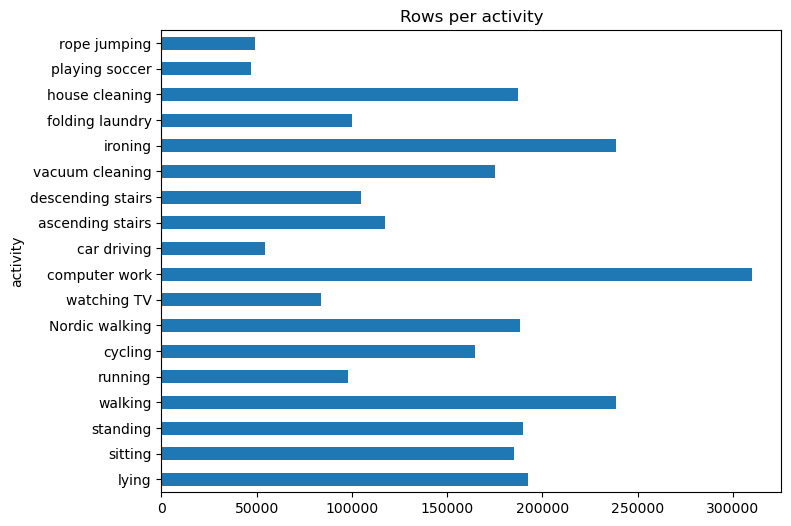

,activity_id,n,activity,pct
0,1,192523,lying,7.065186
1,2,185188,sitting,6.796007
2,3,189931,standing,6.970065
3,4,238761,walking,8.762023
4,5,98199,running,3.603695
5,6,164600,cycling,6.040471
6,7,188107,Nordic walking,6.903128
7,9,83646,watching TV,3.069631
8,10,309935,computer work,11.373958
9,11,54519,car driving,2.000732


In [8]:
print("Transient activity 0 rows (excluded below):", q(f"SELECT COUNT(*) AS n FROM {T} WHERE activity_id = 0").n[0])
cls = q(f"SELECT activity_id, COUNT(*) AS n FROM {T} WHERE activity_id > 0 GROUP BY 1 ORDER BY 1")
cls["activity"] = cls.activity_id.map(schema.ACTIVITY_NAMES)
cls["pct"] = 100 * cls.n / cls.n.sum()
ax = cls.set_index("activity").n.plot.barh(figsize=(8, 6)); ax.set_title("Rows per activity"); plt.show()
cls

### Per-subject counts and activity coverage

    subject_id   session       n  n_activities
0          101  optional  319352             5
1          101  protocol  376417            13
2          102  protocol  447000            13
3          103  protocol  252833             9
4          104  protocol  329576            12
5          105  optional  154773             3
6          105  protocol  374783            13
7          106  optional  129963             4
8          106  protocol  361817            13
9          107  protocol  313599            12
10         108  optional  180412             5
11         108  protocol  408031            13
12         109  optional  193472             5
13         109  protocol    8477             2 
Total rows: 3850505


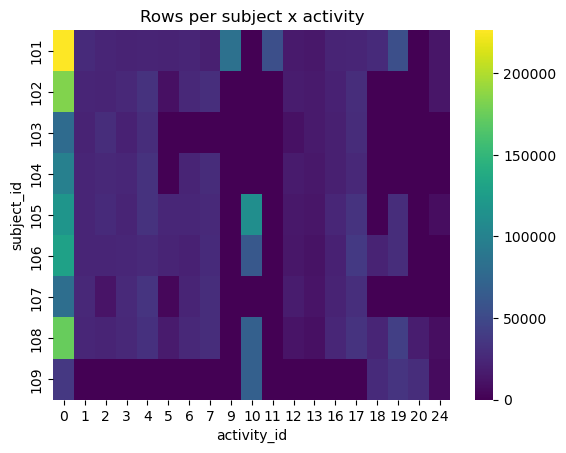

In [9]:
subj = q(f"SELECT subject_id, session, COUNT(*) AS n, COUNT(DISTINCT activity_id) AS n_activities FROM {T} GROUP BY 1,2 ORDER BY 1,2")
print(subj, "\nTotal rows:", subj.n.sum())
sa = q(f"SELECT subject_id, activity_id, COUNT(*) AS n FROM {T} GROUP BY 1,2").pivot(index="subject_id", columns="activity_id", values="n").fillna(0)
sns.heatmap(sa, cmap="viridis"); plt.title("Rows per subject x activity"); plt.show()

### Missingness (heart rate is sparse, ~9 Hz vs 100 Hz)

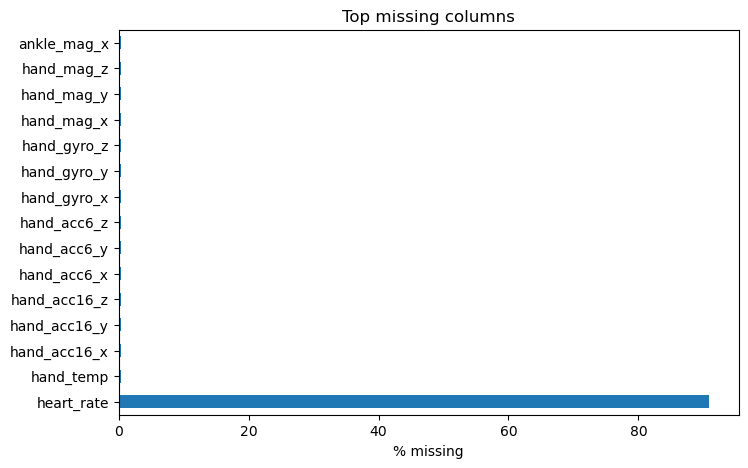

,subject_id,hr_missing_pct
0,101,90.862197
1,102,90.873602
2,103,90.865116
3,104,90.862502
4,105,90.866122
5,106,90.868884
6,107,90.865405
7,108,90.885098
8,109,90.882351


In [10]:
cols = [c for c in schema.CURATED_COLUMNS if c not in ("timestamp", "activity_id")]
sel = ", ".join(f"AVG(CASE WHEN {c} IS NULL THEN 1.0 ELSE 0.0 END) AS {c}" for c in cols)
miss = q(f"SELECT {sel} FROM {T}").iloc[0].astype(float).sort_values(ascending=False) * 100
miss.head(15).plot.barh(figsize=(8, 5)); plt.xlabel("% missing"); plt.title("Top missing columns"); plt.show()
q(f"SELECT subject_id, 100*AVG(CASE WHEN heart_rate IS NULL THEN 1.0 ELSE 0.0 END) AS hr_missing_pct FROM {T} GROUP BY 1 ORDER BY 1")

### Sensor distributions (1% sample drawn in Athena)

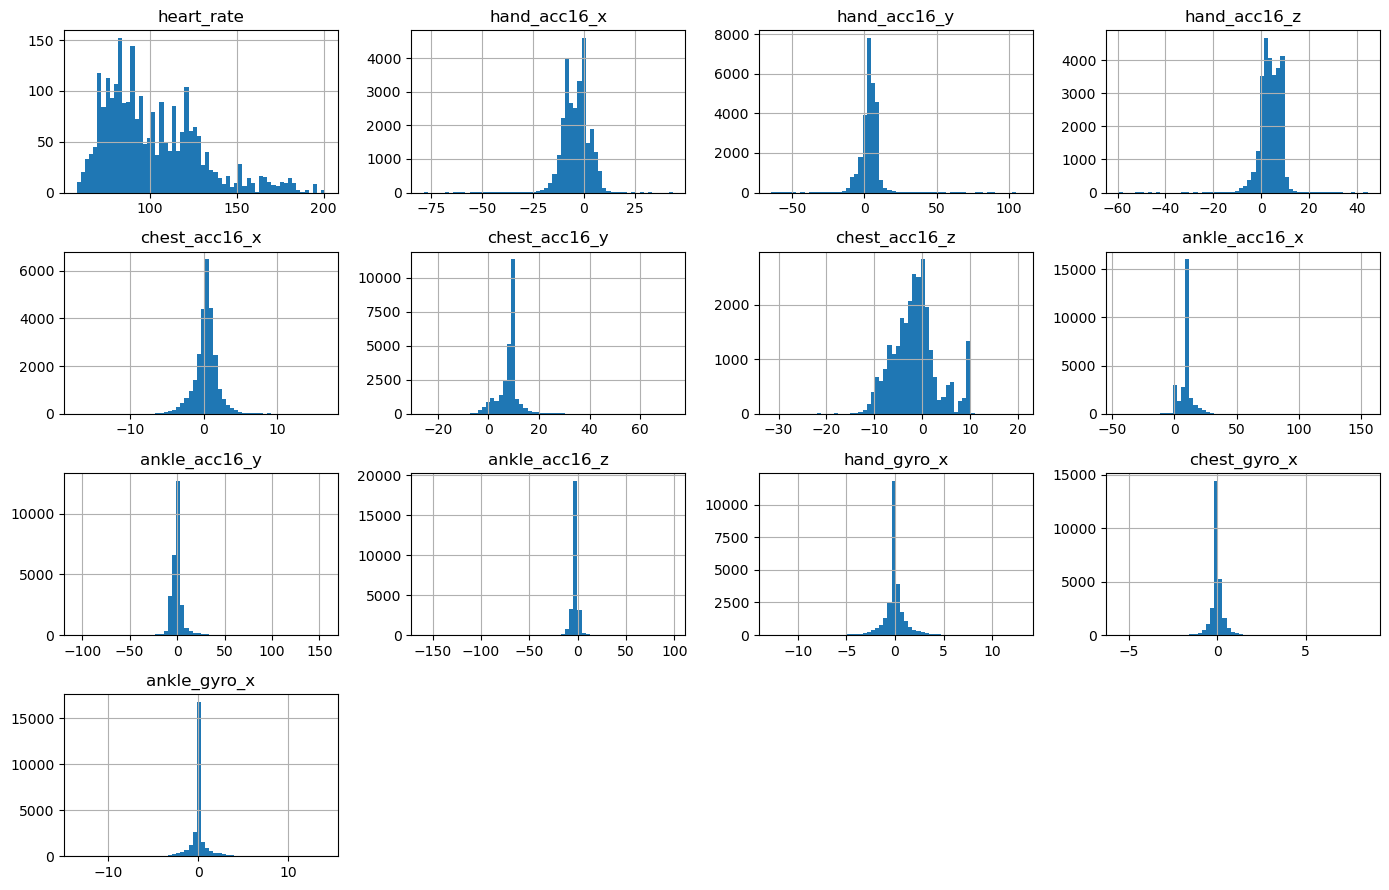

In [11]:
sample_cols = ["activity_id", "heart_rate", "hand_acc16_x", "hand_acc16_y", "hand_acc16_z", "chest_acc16_x",
               "chest_acc16_y", "chest_acc16_z", "ankle_acc16_x", "ankle_acc16_y", "ankle_acc16_z",
               "hand_gyro_x", "chest_gyro_x", "ankle_gyro_x"]
smp = q(f"SELECT {', '.join(sample_cols)} FROM {T} WHERE activity_id > 0 AND rand() < 0.01")
smp.drop(columns="activity_id").hist(figsize=(14, 9), bins=60); plt.tight_layout(); plt.show()

### Correlations

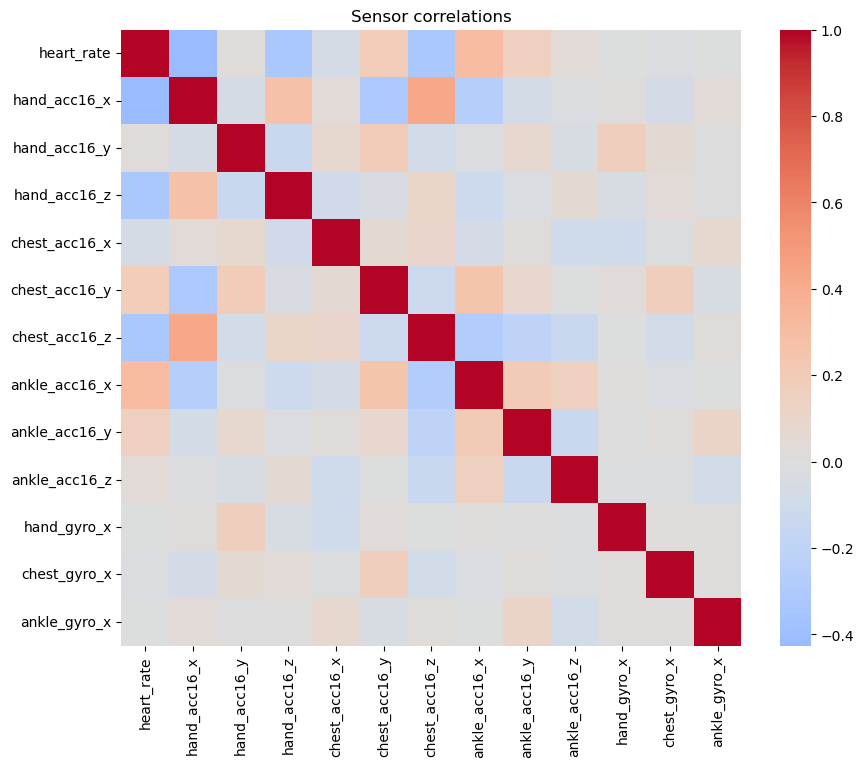

In [12]:
plt.figure(figsize=(10, 8)); sns.heatmap(smp.drop(columns="activity_id").corr(), cmap="coolwarm", center=0); plt.title("Sensor correlations"); plt.show()

### Activity durations (100 Hz)

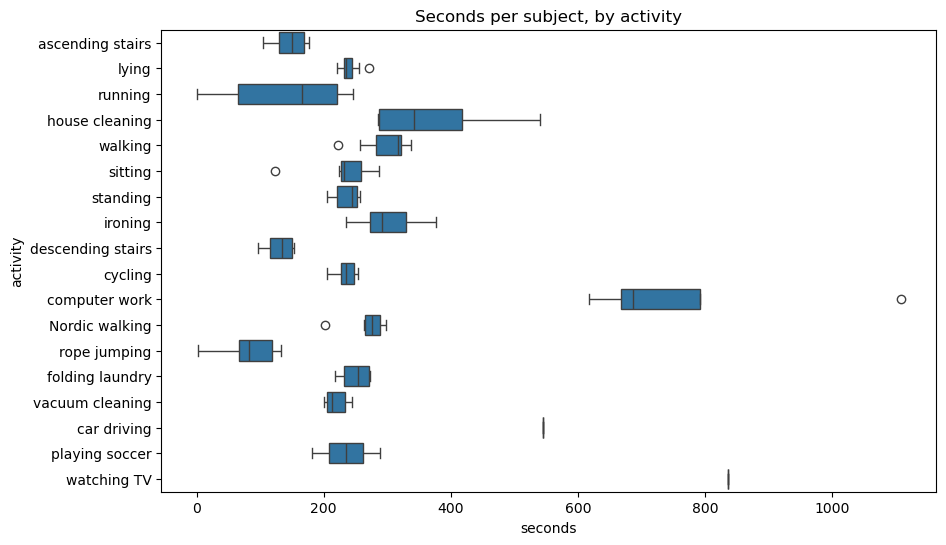

In [13]:
dur = q(f"SELECT subject_id, activity_id, COUNT(*)/100.0 AS seconds FROM {T} WHERE activity_id > 0 GROUP BY 1,2")
dur["activity"] = dur.activity_id.map(schema.ACTIVITY_NAMES)
plt.figure(figsize=(10, 6)); sns.boxplot(data=dur, y="activity", x="seconds"); plt.title("Seconds per subject, by activity"); plt.show()

### Time series per activity (subject 101, protocol, chest accelerometer)

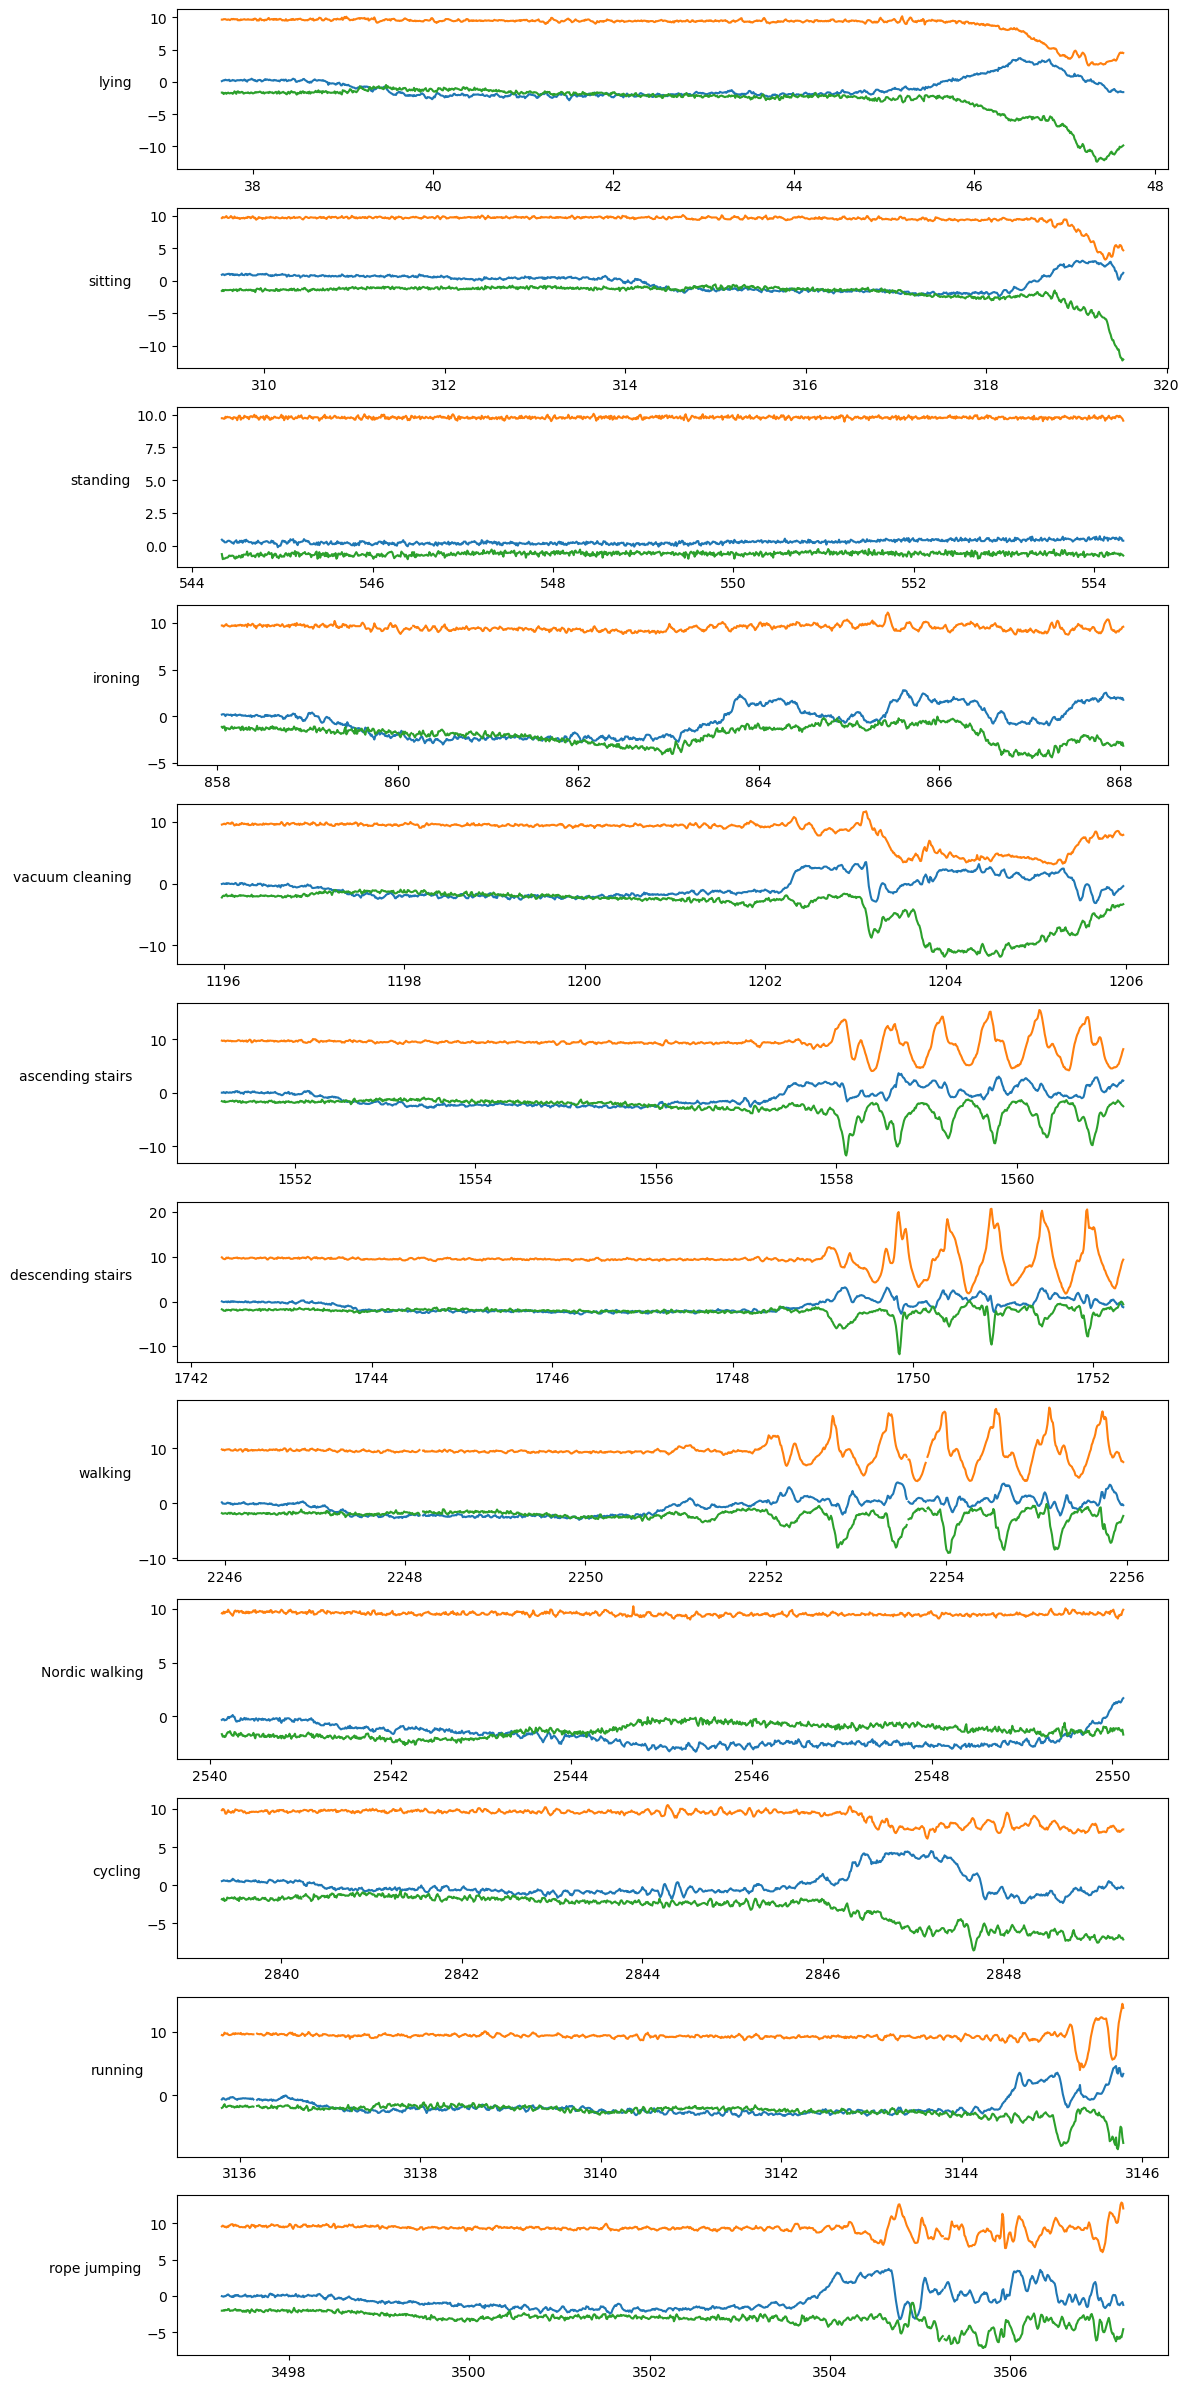

In [14]:
ts = q(f"SELECT \"timestamp\", activity_id, chest_acc16_x, chest_acc16_y, chest_acc16_z FROM {T} WHERE subject_id = 101 AND session = 'protocol' ORDER BY \"timestamp\"")
acts = [a for a in ts.activity_id.unique() if a > 0]
if not acts:
    print("No data for subject 101 / protocol")
else:
  fig, axes = plt.subplots(len(acts), 1, figsize=(12, 2 * len(acts)))
  for ax, a in zip(np.atleast_1d(axes), acts):
    seg = ts[ts.activity_id == a].head(1000)
    ax.plot(seg.timestamp, seg[["chest_acc16_x", "chest_acc16_y", "chest_acc16_z"]]); ax.set_ylabel(schema.ACTIVITY_NAMES[a], rotation=0, ha="right")
  plt.tight_layout(); plt.show()

### Findings (feeds feature engineering)

Confirm against the plots above after running:

- **Class imbalance:** activity 0 (transient/other) is the largest class and must be removed or relabeled; several activities (e.g. 9, 10, 11, 12, 13, 16-20, 24) are rare or absent for some subjects (see the subject x activity heatmap), so subject-aware splits must handle missing classes.
- **Heart rate missingness:** HR is far sparser than IMU columns (~9 Hz vs 100 Hz); forward-fill/interpolate in feature engineering per subject and session, never across subjects.
- **Sensor scale:** acceleration, gyroscope and magnetometer ranges differ by orders of magnitude and by placement; standardize per channel, fit on train only.
- **Redundancy:** acc16 and acc6 channels are highly correlated; consider keeping only acc16.
- **Durations:** activity durations vary widely per subject, so windows per class are uneven; use class weights or resampling.
- **Subject variability:** per-subject distributions differ, motivating subject-aware (not row-random) splitting.

## Feature engineering and SageMaker Feature Store (run in SageMaker Studio)

Builds 512-sample / 50%-overlap window features from curated Parquet and ingests them into an **offline-only** feature group (record id `window_id`). Uses existing `LabRole`; no IAM changes.

In [15]:
import re, io, time
import pandas as pd
from src.pamap2 import features as F
FG_NAME = cfg["feature_group"]
print("Feature group:", FG_NAME)

Feature group: pamap2-har-windows


### Build window features per curated partition

In [16]:
prefix = f"{cfg['s3_prefixes']['curated']}pamap2/"
keys = []
for page in s3.get_paginator("list_objects_v2").paginate(Bucket=cfg["bucket"], Prefix=prefix):
    keys += [o["Key"] for o in page.get("Contents", []) if o["Key"].endswith(".parquet")]
pat = re.compile(r"session=([^/]+)/subject_id=(\d+)/")
parts = []
for k in keys:
    m = pat.search(k)
    if m is None:
        print("Skipping non-matching key:", k)
        continue
    parts.append((m.group(1), int(m.group(2)), k))
parts.sort()
INGEST_TIME = time.time()   # one event_time per run
print(len(parts), "curated partitions")
frames = []
for sess, subj, key in parts:
    raw = pd.read_parquet(io.BytesIO(s3.get_object(Bucket=cfg["bucket"], Key=key)["Body"].read()))
    fr = F.build_feature_frame(raw, subj, sess, ingest_time=INGEST_TIME)
    print(f"{sess}/{subj}: {len(raw)} rows -> {len(fr)} windows")
    frames.append(fr)
feat = pd.concat(frames, ignore_index=True)
assert feat["window_id"].is_unique
print("Total windows:", len(feat), "| features:", len(F.FEATURE_COLUMNS))

14 curated partitions
optional/101: 319352 rows -> 856 windows
optional/105: 154773 rows -> 545 windows
optional/106: 129963 rows -> 439 windows
optional/108: 180412 rows -> 593 windows
optional/109: 193472 rows -> 620 windows
protocol/101: 376417 rows -> 978 windows
protocol/102: 447000 rows -> 1028 windows
protocol/103: 252833 rows -> 683 windows
protocol/104: 329576 rows -> 904 windows
protocol/105: 374783 rows -> 1063 windows
protocol/106: 361817 rows -> 974 windows
protocol/107: 313599 rows -> 909 windows
protocol/108: 408031 rows -> 1022 windows
protocol/109: 8477 rows -> 25 windows
Total windows: 10639 | features: 128


In [17]:
from src.pamap2.schema import ACTIVITY_NAMES
display(feat.groupby("activity_id").size().rename("windows").to_frame()
        .assign(activity=lambda d: d.index.map(ACTIVITY_NAMES)))
display(feat.pivot_table(index="subject_id", columns="activity_id", values="window_id", aggfunc="count").fillna(0).astype(int))

,windows,activity
activity_id,,
1,751,lying
2,724,sitting
3,741,standing
4,931,walking
5,381,running
6,643,cycling
7,736,Nordic walking
9,327,watching TV
10,1210,computer work


activity_id,1,2,3,4,5,6,7,9,10,11,12,13,16,17,18,19,20,24
subject_id,,,,,,,,,,,,,,,,,,
101,106,92,85,86,83,92,80,327,0,213,63,58,90,92,105,211,0,51
102,91,87,100,127,36,98,116,0,0,0,68,59,81,113,0,0,0,52
103,86,113,80,114,0,0,0,0,0,0,41,60,80,109,0,0,0,0
104,90,100,96,124,0,89,108,0,0,0,65,55,79,98,0,0,0,0
105,93,105,86,125,96,96,103,0,433,0,56,50,95,129,0,112,0,29
106,91,90,95,100,89,80,104,0,241,0,51,44,82,148,86,112,0,0
107,100,48,101,132,13,89,112,0,0,0,69,45,85,115,0,0,0,0
108,94,89,98,123,64,99,113,0,268,0,46,38,95,129,92,163,70,34
109,0,0,0,0,0,0,0,0,268,0,0,0,0,0,106,134,112,25


### Create the feature group - offline store only

In [18]:
from botocore.exceptions import ClientError
sm = session.client("sagemaker")
fs_rt = session.client("sagemaker-featurestore-runtime")

def _fs_type(dtype):
    if pd.api.types.is_integer_dtype(dtype):
        return "Integral"
    if pd.api.types.is_float_dtype(dtype):
        return "Fractional"
    return "String"
wanted = {c: _fs_type(feat[c].dtype) for c in feat.columns}

def describe():
    try:
        return sm.describe_feature_group(FeatureGroupName=FG_NAME)
    except ClientError as e:
        if e.response["Error"]["Code"] in ("ResourceNotFound", "ResourceNotFoundException"):
            return None
        raise

desc = describe()
if desc is None:
    sm.create_feature_group(
        FeatureGroupName=FG_NAME,
        RecordIdentifierFeatureName="window_id",
        EventTimeFeatureName="event_time",
        FeatureDefinitions=[{"FeatureName": c, "FeatureType": t} for c, t in wanted.items()],
        OnlineStoreConfig={"EnableOnlineStore": False},
        OfflineStoreConfig={"S3StorageConfig": {"S3Uri": s3_uri(cfg, "features", "offline-store/")},
                            "DisableGlueTableCreation": False},
        RoleArn=cfg["role_arn"])
    print("Creating feature group...")
else:
    existing = {f["FeatureName"]: f["FeatureType"] for f in desc["FeatureDefinitions"]}
    if existing != wanted:
        diff = {k for k in set(wanted) & set(existing) if wanted[k] != existing[k]}
        raise RuntimeError(f"Existing feature group {FG_NAME} has a different schema; "
                           f"missing={set(wanted)-set(existing)} extra={set(existing)-set(wanted)} "
                           f"type_mismatch={diff}")
    print("Reusing existing feature group (schema matches).")
deadline = time.time() + 30 * 60
while True:
    d = sm.describe_feature_group(FeatureGroupName=FG_NAME)
    status = d["FeatureGroupStatus"]
    if status == "Created":
        break
    if status in ("Deleting", "CreateFailed", "DeleteFailed"):
        raise RuntimeError(f"Feature group status: {status} - {d.get('FailureReason')}")
    if time.time() > deadline:
        raise TimeoutError(f"Feature group not Created after 30 min (status {status})")
    time.sleep(5)
print("Feature group status:", status)

Creating feature group...
Feature group status: Created


### Ingest 

In [19]:
from concurrent.futures import ThreadPoolExecutor

def _record(row):
    return [{"FeatureName": c, "ValueAsString": str(v)} for c, v in row.items() if pd.notna(v)]

def _put(row):
    for attempt in range(5):
        try:
            fs_rt.put_record(FeatureGroupName=FG_NAME, Record=_record(row))
            return None
        except ClientError as e:
            if attempt == 4:
                return (row["window_id"], str(e))
            time.sleep(2 ** attempt)

rows = feat.to_dict(orient="records")
with ThreadPoolExecutor(max_workers=8) as ex:
    failed = [r for r in ex.map(_put, rows) if r is not None]
assert not failed, f"Ingest failed rows ({len(failed)}): {failed[:5]}"
print("Ingested", len(feat), "records")

Ingested 10639 records


### Verify record count on the offline table

The offline store lags ingestion by several minutes; this polls for up to 20 minutes.

In [20]:
d = sm.describe_feature_group(FeatureGroupName=FG_NAME)
dc = d["OfflineStoreConfig"]["DataCatalogConfig"]
tbl = f'"{dc["Database"]}"."{dc["TableName"]}"'
print("Offline table:", tbl)
ids = set(feat["window_id"])
n = total = 0
for _ in range(40):
    stored = run(f"SELECT DISTINCT window_id FROM {tbl}", database=dc["Database"]).window_id
    total = len(stored)
    n = int(stored.isin(ids).sum())
    if n >= len(feat):
        break
    time.sleep(30)
print("Current-run windows in offline store:", n, "| generated:", len(feat),
      "| extra (stale) window_ids:", total - n)
assert n == len(feat), "offline store is missing windows from this run (wait and re-run this cell)"

Offline table: "sagemaker_featurestore"."pamap2_har_windows_1791734767"
Current-run windows in offline store: 10639 | generated: 10639 | extra (stale) window_ids: 0


## Data split 40/10/10/40 

Reads the offline feature store via Athena and assigns chronological splits within each subject+activity (train 40% / validation 10% / test 10% / production 40%, with a 1-window gap dropped between blocks). Test and production contain subjects seen in training, so scores are optimistic relative to leave-one-subject-out evaluation.

In [21]:
import json
from src.pamap2 import features as F
from src.pamap2.split import (assign_splits, split_shares, SPLITS, restrict_to_train_classes,
                              class_coverage)
FG_NAME = cfg["feature_group"]
sm = session.client("sagemaker")
dc = sm.describe_feature_group(FeatureGroupName=FG_NAME)["OfflineStoreConfig"]["DataCatalogConfig"]
tbl = f'"{dc["Database"]}"."{dc["TableName"]}"'
print("Offline table:", tbl)

Offline table: "sagemaker_featurestore"."pamap2_har_windows_1791734767"


### Load latest record 

In [22]:
sql = f"""
SELECT * FROM (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY window_id ORDER BY event_time DESC, write_time DESC) AS rn
  FROM {tbl}
) WHERE rn = 1 AND is_deleted = false
"""
df = run(sql, database=dc["Database"]).drop(columns=["rn"])
meta = ["window_id", "subject_id", "session", "start_idx", "activity_id", "intensity", "event_time", "t_start"]
df = df[meta + F.FEATURE_COLUMNS]
print(df.shape, "windows:", df.window_id.nunique())

(10639, 136) windows: 10639


### Assign splits and report shares

In [23]:
out = assign_splits(df)
print(f"Dropped {len(df) - len(out)} gap windows; kept {len(out)}")
print("Overall share (%):"); print(split_shares(out))
print("Per activity:"); display(split_shares(out, "activity_id"))
print("Per subject:"); display(split_shares(out, "subject_id"))
shares = split_shares(out)
for k, t in zip(SPLITS, (40, 10, 10, 40)):
    assert abs(shares[k] - t) <= 5, f"{k} share {shares[k]} outside +/-5 of {t}"
assert out.window_id.is_unique

out, dropped, classes = restrict_to_train_classes(out)
print("Classes in train:", classes)
print("Dropped (class absent from train), per split:", dropped.to_dict() or "none")
print("Class coverage (windows per activity x split):"); display(class_coverage(out))

Dropped 318 gap windows; kept 10321
Overall share (%):
split
train         41.2
validation     9.3
test           9.3
production    40.3
Name: proportion, dtype: float64
Per activity:


split,train,validation,test,production
activity_id,,,,
1,41.1,9.2,9.2,40.4
2,41.4,9.1,9.1,40.3
3,41.1,9.3,9.3,40.2
4,41.1,9.3,9.3,40.4
5,41.9,8.8,8.8,40.5
6,41.5,9.3,9.3,39.9
7,41.1,9.2,9.2,40.4
9,40.4,9.9,9.9,39.8
10,40.3,9.8,9.8,40.2


Per subject:


split,train,validation,test,production
subject_id,,,,
101,41.0,9.3,9.3,40.4
102,41.3,9.3,9.3,40.1
103,41.4,9.1,9.1,40.4
104,41.4,9.3,9.3,40.0
105,41.0,9.4,9.4,40.2
106,41.2,9.3,9.3,40.3
107,41.6,9.0,9.0,40.4
108,41.3,9.3,9.3,40.2
109,41.0,9.4,9.4,40.3


Classes in train: [1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 16, 17, 18, 19, 20, 24]
Dropped (class absent from train), per split: none
Class coverage (windows per activity x split):


split,train,validation,test,production
activity_id,,,,
1,299,67,67,294
2,290,64,64,282
3,295,67,67,288
4,373,84,84,366
5,152,32,32,147
6,258,58,58,248
7,294,66,66,289
9,131,32,32,129
10,483,117,117,481


### Write split files to S3

In [24]:
import pathlib
label_map = {int(a): i for i, a in enumerate(classes)}   # train classes only; XGBoost needs 0..K-1
out = out.assign(label=out.activity_id.map(label_map)).sort_values("window_id").reset_index(drop=True)
cols = list(F.FEATURE_COLUMNS)
tmp = pathlib.Path("/tmp/pamap2_splits"); tmp.mkdir(parents=True, exist_ok=True)
def put(path, key):
    s3.upload_file(str(path), cfg["bucket"], f"{cfg['s3_prefixes']['splits']}{key}")
for name in SPLITS:
    part = out[out.split == name].reset_index(drop=True)
    p = tmp / f"{name}.parquet"; part[meta + ["label", "split"] + cols].to_parquet(p, index=False); put(p, p.name)
    if name != "production":
        c = tmp / f"{name}.csv"                                  # label first, no header
        part[["label"] + cols].to_csv(c, header=False, index=False); put(c, c.name)
    print(name, len(part))
(tmp / "feature_columns.json").write_text(json.dumps(cols)); put(tmp / "feature_columns.json", "feature_columns.json")
(tmp / "label_map.json").write_text(json.dumps([{"activity_id": a, "label": l} for a, l in label_map.items()])); put(tmp / "label_map.json", "label_map.json")
print("Written to", s3_uri(cfg, "splits"))

train 4253
validation 956
test 956
production 4156
Written to s3://pamap2-har-887757489409-us-east-1/features/splits/
